<a href="https://colab.research.google.com/github/ngphuc-ict/pm25-forecasting-rnn/blob/main/Hanoi_PM25_Vanilla_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# SETUP, ĐỌC DỮ LIỆU & TIỀN XỬ LÝ
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 1. Đọc dữ liệu từ file CSV của bạn
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/datasets/hanoi_aqi_ml_ready_fixed.csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# 2. ĐƯA ĐẦY ĐỦ CÁC BIẾN SỐ QUAN TRỌNG TRONG FILE VÀO ĐÂY
features = [
    'pm25',
    'temperature', 'humidity', 'dew_point', 'precipitation', 'rain',
    'pressure_msl', 'surface_pressure', 'cloud_cover', 'wind_speed',
    'wind_direction', 'wind_gusts', 'hour', 'day_of_week', 'is_weekend', 'is_dry_season',
    'pm25_lag1', 'pm25_lag24', 'pm25_lag168',
    'pm25_rolling_3h', 'pm25_rolling_24h', 'pm25_rolling_7d', 'pm25_rolling_24h_std',
    'wind_u', 'wind_v', 'temp_humidity', 'pressure_diff', 'is_raining'
]
data = df[features].dropna().values

# 3. Chia tập dữ liệu theo tỷ lệ chuẩn: 60% Train / 20% Val / 20% Test
n = len(data)
train_end = int(n * 0.6)
val_end = int(n * 0.8)

train_data = data[:train_end]
val_data = data[train_end:val_end]
test_data = data[val_end:]

# 4. Chuẩn hóa dữ liệu toàn bộ đặc trưng về khoảng [0, 1]
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_data)
val_scaled = scaler.transform(val_data)
test_scaled = scaler.transform(test_data)

print(f"Tổng số đặc trưng đầu vào mô hình: {len(features)}")
print(f"Kích thước tập Train: {train_scaled.shape} | Tập Val: {val_scaled.shape} | Tập Test: {test_scaled.shape}")

Tổng số đặc trưng đầu vào mô hình: 28
Kích thước tập Train: (8670, 28) | Tập Val: (2890, 28) | Tập Test: (2891, 28)


In [ ]:
# SLIDING WINDOW & DATALOADER
def create_dataset(data, lookback, target_col_idx=0):
    X, y = [], []
    for i in range(len(data) - lookback):
        X.append(data[i:(i + lookback)])
        y.append(data[i + lookback, target_col_idx])
    return np.array(X), np.array(y)

LOOKBACK = 24
TARGET_COL_IDX = 0

# Tạo tập dữ liệu chuỗi thời gian cho cả 3 tập
X_train, y_train = create_dataset(train_scaled, LOOKBACK, TARGET_COL_IDX)
X_val, y_val = create_dataset(val_scaled, LOOKBACK, TARGET_COL_IDX)
X_test, y_test = create_dataset(test_scaled, LOOKBACK, TARGET_COL_IDX)

# Chuyển đổi sang PyTorch Tensor
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(-1)

X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32).unsqueeze(-1)

X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32).unsqueeze(-1)

# Đóng gói vào DataLoader (Đầy đủ train_loader và val_loader)
BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=BATCH_SIZE, shuffle=False)

print(f"Cấu trúc đầu vào mô hình (X_train): {X_train_t.shape}")

Cấu trúc đầu vào mô hình (X_train): torch.Size([8646, 24, 28])


In [ ]:
# KIẾN TRÚC MÔ HÌNH
class ExtractLastStep(nn.Module):
    def forward(self, rnn_output):
        out, _ = rnn_output
        return out[:, -1, :] # Lấy trạng thái ở bước thời gian cuối cùng

INPUT_SIZE = len(features)
HIDDEN_SIZE = 64
OUTPUT_SIZE = 1

model = nn.Sequential(
    nn.RNN(
        input_size=INPUT_SIZE,
        hidden_size=HIDDEN_SIZE,
        num_layers=1,
        batch_first=True),
    ExtractLastStep(),
    nn.Dropout(p=0.2),
    nn.Linear(in_features=HIDDEN_SIZE, out_features=OUTPUT_SIZE)
).to(device)

print(model)

Sequential(
  (0): RNN(28, 64, batch_first=True)
  (1): ExtractLastStep()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=64, out_features=1, bias=True)
)


In [ ]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)

In [ ]:
# TRAINING & EARLY STOPPING
EPOCHS = 50
PATIENCE = 7 # Số epoch kiên nhẫn chờ đợi nếu Val Loss không cải thiện
best_val_loss = float('inf')
epochs_no_improve = 0

# --- LƯU LỊCH SỬ ĐỂ VẼ BIỂU ĐỒ LÝ TƯỞNG ---
train_losses = []
val_losses = []

print("Bắt đầu huấn luyện với Early Stopping...")
for epoch in range(EPOCHS):
    # Training Phase
    model.train()
    train_loss = 0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(batch_x), batch_y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * batch_x.size(0)

    train_loss /= len(train_loader.dataset)
    train_losses.append(train_loss) # <-- Thêm dòng này

    # Validation Phase
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            val_loss += criterion(model(batch_x), batch_y).item() * batch_x.size(0)
    val_loss /= len(val_loader.dataset)
    val_losses.append(val_loss) # <-- Thêm dòng này

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.5f} | Val Loss: {val_loss:.5f}")

    # Kích hoạt Early Stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(model.state_dict(), 'best_rnn_model.pth')
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"Kích hoạt Early Stopping tại Epoch {epoch+1}. Đã khôi phục checkpoint tốt nhất!")
            break

# Load lại mô hình xịn nhất trước khi sang phần đánh giá
model.load_state_dict(torch.load('best_rnn_model.pth'))

Bắt đầu huấn luyện với Early Stopping...
Epoch 1/50 | Train Loss: 0.00666 | Val Loss: 0.00153
Epoch 2/50 | Train Loss: 0.00242 | Val Loss: 0.00132
Epoch 3/50 | Train Loss: 0.00184 | Val Loss: 0.00119
Epoch 4/50 | Train Loss: 0.00162 | Val Loss: 0.00122
Epoch 5/50 | Train Loss: 0.00148 | Val Loss: 0.00111
Epoch 6/50 | Train Loss: 0.00136 | Val Loss: 0.00105
Epoch 7/50 | Train Loss: 0.00129 | Val Loss: 0.00110
Epoch 8/50 | Train Loss: 0.00123 | Val Loss: 0.00103
Epoch 9/50 | Train Loss: 0.00118 | Val Loss: 0.00104
Epoch 10/50 | Train Loss: 0.00117 | Val Loss: 0.00100
Epoch 11/50 | Train Loss: 0.00117 | Val Loss: 0.00124
Epoch 12/50 | Train Loss: 0.00119 | Val Loss: 0.00102
Epoch 13/50 | Train Loss: 0.00115 | Val Loss: 0.00112
Epoch 14/50 | Train Loss: 0.00113 | Val Loss: 0.00101
Epoch 15/50 | Train Loss: 0.00108 | Val Loss: 0.00104
Epoch 16/50 | Train Loss: 0.00105 | Val Loss: 0.00102
Epoch 17/50 | Train Loss: 0.00108 | Val Loss: 0.00108
Kích hoạt Early Stopping tại Epoch 17. Đã khôi phụ

<All keys matched successfully>

--- HIỆU NĂNG MÔ HÌNH ---
Thời gian xử lý trung bình: 0.35 ms/mẫu (Khung hình/giây: 2874.15 FPS)

--- ĐỘ CHÍNH XÁC ---
RMSE: 6.9895
MAE:  5.0668


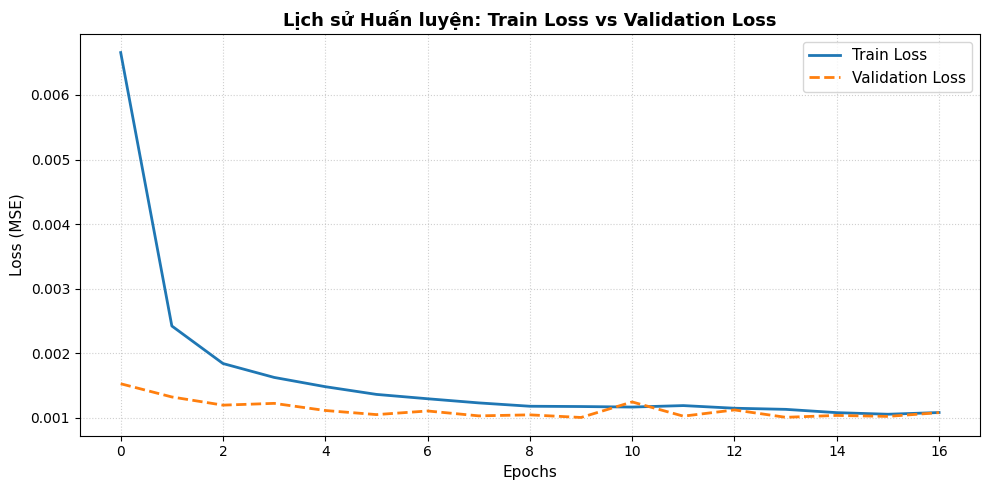

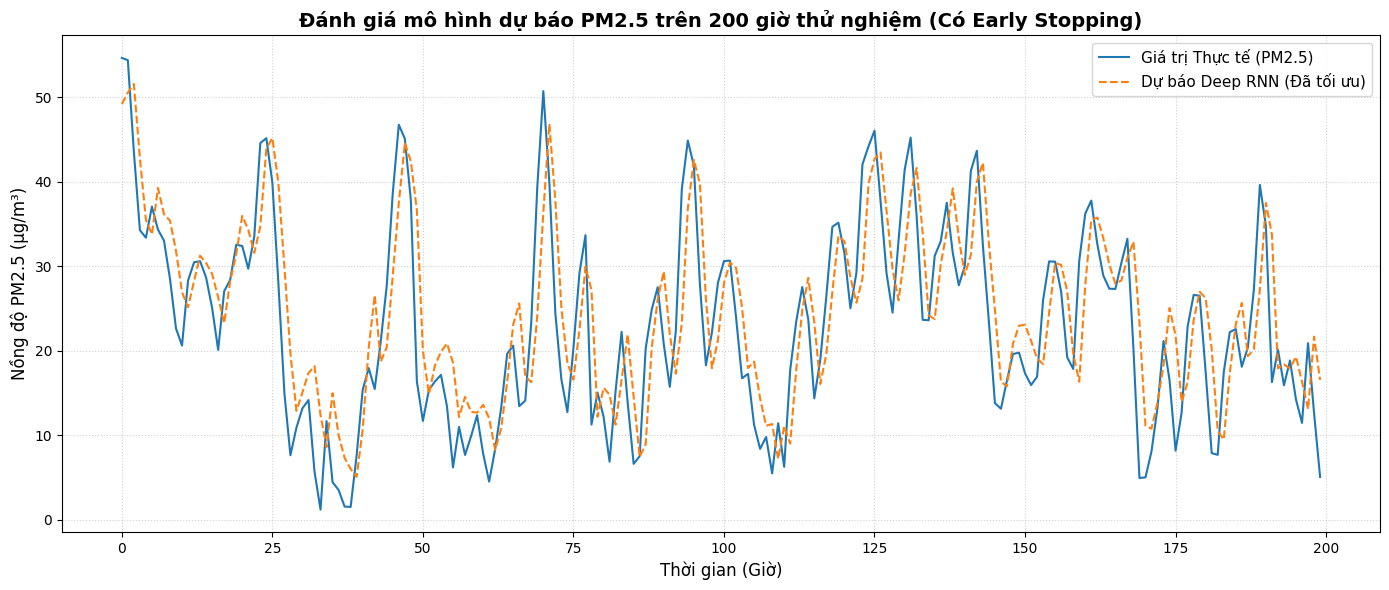

In [ ]:
# ĐÁNH GIÁ, BENCHMARK & TRỰC QUAN HÓA
model.eval()

# 1. Benchmark Tốc độ suy luận (Inference Speed)
sample_input = X_test_t[:1].to(device)
for _ in range(10): _ = model(sample_input) # Warm-up GPU

iterations = 50
start_time = time.time()
with torch.no_grad():
    for _ in range(iterations):
        _ = model(sample_input)
end_time = time.time()

avg_inference_time = (end_time - start_time) / iterations
fps = 1.0 / avg_inference_time
print("--- HIỆU NĂNG MÔ HÌNH ---")
print(f"Thời gian xử lý trung bình: {avg_inference_time*1000:.2f} ms/mẫu (Khung hình/giây: {fps:.2f} FPS)")

# 2. Dự báo và tính sai số
with torch.no_grad():
    predictions_scaled = model(X_test_t.to(device)).cpu().numpy()

dummy_pred = np.zeros((len(predictions_scaled), len(features)))
dummy_pred[:, TARGET_COL_IDX] = predictions_scaled.flatten()
predictions = scaler.inverse_transform(dummy_pred)[:, TARGET_COL_IDX]

dummy_actual = np.zeros((len(y_test), len(features)))
dummy_actual[:, TARGET_COL_IDX] = y_test.flatten()
actuals = scaler.inverse_transform(dummy_actual)[:, TARGET_COL_IDX]

print("\n--- ĐỘ CHÍNH XÁC ---")
print(f"RMSE: {np.sqrt(mean_squared_error(actuals, predictions)):.4f}")
print(f"MAE:  {mean_absolute_error(actuals, predictions):.4f}")

# 3. Trực quan hóa
# --- ĐỒ THỊ 1: BIỂU ĐỒ LOSS MỚI THÊM ---
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss', color='#1f77b4', linewidth=2)
plt.plot(val_losses, label='Validation Loss', color='#ff7f0e', linestyle='--', linewidth=2)
plt.title('Lịch sử Huấn luyện: Train Loss vs Validation Loss', fontsize=13, fontweight='bold')
plt.xlabel('Epochs', fontsize=11)
plt.ylabel('Loss (MSE)', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# --- ĐỒ THỊ 2: ĐỒ THỊ DỰ BÁO PM2.5 ---
plt.figure(figsize=(14, 6))
plt.plot(actuals[:200], label='Giá trị Thực tế (PM2.5)', color='#1f77b4', linewidth=1.5)
plt.plot(predictions[:200], label='Dự báo Deep RNN (Đã tối ưu)', color='#ff7f0e', linestyle='--', linewidth=1.5)
plt.title('Đánh giá mô hình dự báo PM2.5 trên 200 giờ thử nghiệm (Có Early Stopping)', fontsize=14, fontweight='bold')
plt.xlabel('Thời gian (Giờ)', fontsize=12)
plt.ylabel('Nồng độ PM2.5 (µg/m³)', fontsize=12)
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()